In [1]:
%pip install qiskit qiskit-aer matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.2 MB/s eta 0:00:00


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("Quantum Computing Project Started!")


Quantum Computing Project Started!


In [3]:
# Create a circuit with one qubit and one classical bit
qc = QuantumCircuit(1, 1)

# Apply a Hadamard gate
qc.h(0)

# Measure the qubit
qc.measure(0, 0)
# Display the circuit
print(qc.draw())



     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [4]:
qc = QuantumCircuit(1, 1)



In [5]:
qc.h(0)


In [6]:
qc.measure(0, 0)


In [14]:
# Create the quantum simulator
simulator = AerSimulator()

# Run the circuit 1000 times
job = simulator.run(qc, shots=1000)

# Get the results
result = job.result()
counts = result.get_counts()

# Display the results
print("Measurement Results:", counts)
print("Total Measurements:", sum(counts.values()))



Measurement Results: {'0': 480, '1': 520}
Total Measurements: 1000


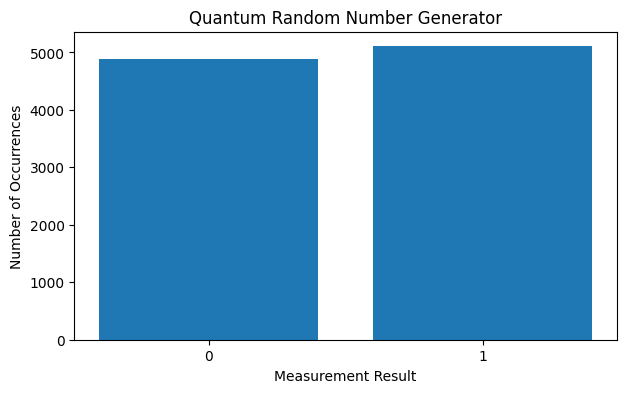

In [13]:
import matplotlib.pyplot as plt

labels = ['0', '1']
values = [counts.get('0', 0), counts.get('1', 0)]

plt.figure(figsize=(7, 4))
plt.bar(labels, values)

plt.title("Quantum Random Number Generator")
plt.xlabel("Measurement Result")
plt.ylabel("Number of Occurrences")

plt.show()

In [10]:
shot_values = [100, 1000, 10000]
results = {}

for shots in shot_values:
    job = simulator.run(qc, shots=shots)
    result = job.result()
    counts = result.get_counts()

    zero_count = counts.get('0', 0)
    one_count = counts.get('1', 0)

    zero_percentage = zero_count / shots * 100
    one_percentage = one_count / shots * 100

    results[shots] = (zero_percentage, one_percentage)

    print(f"\nMeasurements: {shots}")
    print(f"Zeros: {zero_percentage:.2f}%")
    print(f"Ones: {one_percentage:.2f}%")




Measurements: 100
Zeros: 45.00%
Ones: 55.00%

Measurements: 1000
Zeros: 50.60%
Ones: 49.40%

Measurements: 10000
Zeros: 48.94%
Ones: 51.06%


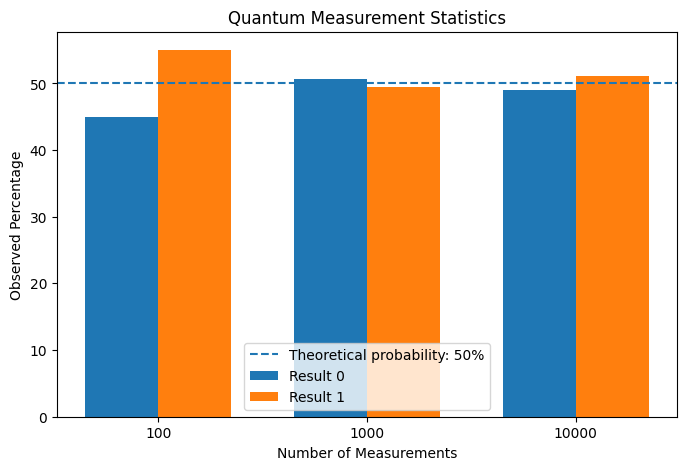

In [11]:

shots = list(results.keys())

zero_values = [results[s][0] for s in shots]
one_values = [results[s][1] for s in shots]

x = range(len(shots))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    [i - width/2 for i in x],
    zero_values,
    width,
    label="Result 0"
)

plt.bar(
    [i + width/2 for i in x],
    one_values,
    width,
    label="Result 1"
)

plt.axhline(
    50,
    linestyle="--",
    label="Theoretical probability: 50%"
)

plt.xticks(list(x), shots)
plt.xlabel("Number of Measurements")
plt.ylabel("Observed Percentage")
plt.title("Quantum Measurement Statistics")
plt.legend()
plt.show()




In [12]:
# Generate 16 binary digits using 16 qubits
qc_string = QuantumCircuit(16, 16)

# Apply a Hadamard gate to every qubit
qc_string.h(range(16))

# Measure every qubit
qc_string.measure(range(16), range(16))

# Run the circuit once
job = simulator.run(qc_string, shots=1)
result = job.result()

# Get the binary outcome
binary_result = list(result.get_counts().keys())[0]

print("Generated binary string:", binary_result)
print("Length:", len(binary_result))

Generated binary string: 1101010100111100
Length: 16
